# SpaceRec C2 xDBiT workflow with OpenPhenom

This notebook follows the public `spacerec.ipynb` step boundaries, starting from the supplied C2 deconvolution. The deconvolution is validated and reused; the expression reference (`mu_ref`), OpenPhenom embedding, tissue mask, Stage 1 model, and Stage 2 model are rebuilt in an isolated run. Existing canonical results are not overwritten.

| Step | Operation |
| --- | --- |
| 1 | Validate supplied deconvolution and rebuild the platform-normalized expression reference |
| 2 | Extract 768-dimensional OpenPhenom grid embeddings and apply the SpaceRec mask |
| 3.1 | Train the grid router/type model |
| 3.2 | Train finetune-mu expression prediction and validate all grid outputs |
| 4 | Display the requested C2 type and Slc17a7 window images |

In [1]:
from __future__ import annotations

import json
import html
import os
import shutil
import subprocess
import sys
import time
from pathlib import Path
from pprint import pprint

# Match the public SpaceRec notebook: select the first GPU exposed by the
# active Slurm allocation before importing PyTorch.
if not os.environ.get('CUDA_VISIBLE_DEVICES') and os.environ.get('SLURM_JOB_ID'):
    gpu_query = subprocess.run(
        ['nvidia-smi', '--query-gpu=index', '--format=csv,noheader'],
        check=True, capture_output=True, text=True, timeout=30,
    ).stdout.splitlines()
    if gpu_query:
        os.environ['CUDA_VISIBLE_DEVICES'] = gpu_query[0].strip()

import anndata as ad
import h5py
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display


def find_spacerec_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        for candidate in (path, path / 'external' / 'SpaceRec'):
            if (candidate / 'spacerec' / 'api.py').is_file():
                return candidate
    raise FileNotFoundError('Could not find the SpaceRec checkout.')


def find_project_root(spacerec_root: Path) -> Path:
    for path in (spacerec_root, *spacerec_root.parents):
        if (path / 'resources' / 'cerebellum' / 'manifest.json').is_file() and (path / 'scripts' / 'handoff_cerebellum_spacerec_v2').is_dir():
            return path
    raise FileNotFoundError('Could not find the project resources and cerebellum workflow scripts.')


def require_files(*paths: Path) -> None:
    missing = [str(path) for path in paths if not path.is_file() or path.stat().st_size == 0]
    if missing:
        raise FileNotFoundError('Missing required files:\n' + '\n'.join(missing))


ROOT = find_spacerec_root()
PROJECT_ROOT = find_project_root(ROOT)
SCRIPT_DIR = PROJECT_ROOT / 'scripts' / 'handoff_cerebellum_spacerec_v2'
RESOURCE_ROOT = PROJECT_ROOT / 'resources' / 'cerebellum'
SAMPLE = 'C2'
SAMPLE_ROOT = RESOURCE_ROOT / SAMPLE
RUN_NAME = os.environ.get('CEREBELLUM_NOTEBOOK_RUN_NAME', 'notebook_run_stepwise')
RUN_ROOT = SAMPLE_ROOT / RUN_NAME
OPENPHENOM_PYTHON = PROJECT_ROOT / 'openphenom_env' / 'bin' / 'python'
manifest = json.loads((RESOURCE_ROOT / 'manifest.json').read_text())
sample_manifest = manifest['samples'][SAMPLE]
paths = {key: SAMPLE_ROOT / value for key, value in sample_manifest.items() if isinstance(value, str) and key != 'source_id'}
if RUN_ROOT.exists() and any(RUN_ROOT.iterdir()):
    raise FileExistsError(f'{RUN_ROOT} is not empty. Set CEREBELLUM_NOTEBOOK_RUN_NAME to a new name for a fresh run.')

os.environ['CEREBELLUM_RUN_VARIANT'] = 'mean8'
os.environ['CEREBELLUM_GRID_SIZE'] = '30'
os.environ['CEREBELLUM_RUN_ROOT'] = str(RUN_ROOT)
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
r_env = Path(os.environ.get('SPACEREC_R_ENV', Path.home() / '.conda' / 'envs' / 'spacerec_r_env'))
require_files(paths['deconv_csv'], paths['st_h5ad'], paths['stage1_st_h5ad'], paths['stage1_genes'], paths['fullres_image'], r_env / 'bin' / 'Rscript', OPENPHENOM_PYTHON)
if not torch.cuda.is_available():
    raise RuntimeError('A CUDA GPU is required for embedding and training.')


def pipeline_environment() -> dict[str, str]:
    env = os.environ.copy()
    env['PYTHONPATH'] = os.pathsep.join([str(PROJECT_ROOT), str(SCRIPT_DIR), env.get('PYTHONPATH', '')]).rstrip(os.pathsep)
    env['SPACEREC_R_ENV'] = str(r_env)
    env['PATH'] = str(r_env / 'bin') + os.pathsep + env.get('PATH', '')
    env['PYTHONUNBUFFERED'] = '1'
    return env


def progress_html(label: str, current: int, total: int | None, status: str) -> HTML:
    percent = 0 if not total else min(100, round(100 * current / total))
    count = status if total is None else f'{current:,}/{total:,} · {status}'
    return HTML(
        f"<div style='font-family:monospace;max-width:760px'>"
        f"<div><b>{html.escape(label)}</b> &nbsp; {percent:3d}% &nbsp; {html.escape(count)}</div>"
        f"<div style='height:12px;background:#e5e7eb;border-radius:6px;overflow:hidden'>"
        f"<div style='height:100%;width:{percent}%;background:#2563eb'></div></div></div>"
    )


def read_progress(kind: str, log_path: Path, progress_path: Path | None, total: int | None) -> tuple[int, int | None]:
    if kind == 'openphenom' and log_path.is_file():
        current = 0
        for line in log_path.read_text(errors='replace').splitlines():
            try:
                event = json.loads(line)
            except json.JSONDecodeError:
                continue
            if event.get('stage') == 'geometry_ready':
                total = int(event['n_patches'])
            elif event.get('stage') == 'extract_progress':
                current = int(event['processed_patches'])
                total = int(event['total_patches'])
        return current, total
    if kind == 'lightning' and progress_path is not None:
        epochs = []
        for metrics_csv in progress_path.glob('lightning_logs/*/metrics.csv'):
            try:
                metrics = pd.read_csv(metrics_csv, usecols=['epoch'])
                epochs.extend(metrics['epoch'].dropna().astype(int).tolist())
            except (OSError, ValueError, pd.errors.EmptyDataError):
                pass
        return (max(epochs) + 1 if epochs else 0), total
    return 0, total


def run_script(
    label: str, script: str, arguments: list[str], outputs: list[Path], *,
    progress_kind: str = 'completion', progress_path: Path | None = None, total: int | None = None,
) -> None:
    if any(path.exists() for path in outputs):
        raise FileExistsError(f'{label}: refusing to reuse or overwrite outputs under {RUN_ROOT}.')
    python_executable = OPENPHENOM_PYTHON if script == 'extract_openphenom.py' else Path(sys.executable)
    command = [str(python_executable), str(SCRIPT_DIR / script), *arguments]
    print('$ ' + ' '.join(command), flush=True)
    log_dir = RUN_ROOT / SAMPLE / 'logs'
    log_dir.mkdir(parents=True, exist_ok=True)
    log_path = log_dir / (script.removesuffix('.py') + '.log')
    progress = display(progress_html(label, 0, total, 'starting'), display_id=True)
    started = time.monotonic()
    with log_path.open('w', encoding='utf-8') as log_handle:
        process = subprocess.Popen(
            command, cwd=PROJECT_ROOT, env=pipeline_environment(),
            stdout=log_handle, stderr=subprocess.STDOUT, text=True,
        )
        while process.poll() is None:
            current, observed_total = read_progress(progress_kind, log_path, progress_path, total)
            status = f'running {time.monotonic() - started:.0f}s'
            progress.update(progress_html(label, current, observed_total, status))
            time.sleep(1)
    if process.returncode != 0:
        progress.update(progress_html(label, 0, total, 'failed'))
        tail = '\n'.join(log_path.read_text(errors='replace').splitlines()[-40:])
        raise subprocess.CalledProcessError(process.returncode, command, output=tail)
    require_files(*outputs)
    final_total = total
    if progress_kind == 'openphenom':
        _, final_total = read_progress(progress_kind, log_path, progress_path, total)
    progress.update(progress_html(label, final_total or 1, final_total or 1, 'complete'))
    print(f'complete; log: {log_path}')


pprint({
    'sample': SAMPLE, 'isolated_run_root': RUN_ROOT,
    'slurm_job_id': os.environ.get('SLURM_JOB_ID'),
    'cuda_visible_devices': os.environ.get('CUDA_VISIBLE_DEVICES'),
    'cuda_device': torch.cuda.get_device_name(0),
    'supplied_deconvolution': paths['deconv_csv'],
    'fresh_run': True,
})

C2 stepwise run configured on Slurm job 50273640; CUDA device: Tesla V100-SXM2-32GB
Fresh isolated output: resources/cerebellum/C2/notebook_run_stepwise/C2


## Step 1: supplied deconvolution and newly built expression reference

As in the public SpaceRec notebook, the supplied deconvolution is validated and reused rather than recomputed. The expression reference is rebuilt from the independent cerebellar atlas and real C2 spatial counts through the dedicated SpaceRec/RCTD platform-normalization workflow, followed by section-specific 8,000-HVG selection. No existing `mu_ref` is read into the new run.

In [2]:
adata = ad.read_h5ad(paths['st_h5ad'], backed='r')
spot_ids = adata.obs_names.astype(str).tolist()
adata.file.close()
deconv = pd.read_csv(paths['deconv_csv'], index_col=0)
deconv.index = deconv.index.astype(str)
values = deconv.to_numpy(dtype=np.float64)
if deconv.index.tolist() != spot_ids:
    raise ValueError('Supplied deconvolution rows do not exactly match the C2 xDBiT spot order.')
if not np.isfinite(values).all() or np.any(values < 0):
    raise ValueError('Supplied deconvolution must be finite and nonnegative.')
if not np.allclose(values.sum(axis=1), 1.0, atol=1e-6):
    raise ValueError('Supplied deconvolution rows must sum to one.')

input_dir = RUN_ROOT / SAMPLE / 'input'
input_dir.mkdir(parents=True, exist_ok=True)
run_deconv = input_dir / 'RCTD_merged8.csv'
if run_deconv.exists():
    existing = pd.read_csv(run_deconv, index_col=0)
    if existing.index.astype(str).tolist() != deconv.index.tolist() or not np.allclose(existing, deconv):
        raise ValueError('Existing notebook-run deconvolution differs from the supplied file.')
else:
    shutil.copy2(paths['deconv_csv'], run_deconv)
for source, target in [
    (paths['stage1_st_h5ad'], input_dir / 'st_stage1.h5ad'),
    (paths['stage1_genes'], input_dir / 'stage1_placeholder_genes.txt'),
]:
    target.symlink_to(os.path.relpath(source.resolve(), target.parent))
pprint({'reused_supplied_deconvolution': True, 'n_spots': len(deconv), 'cell_types': deconv.columns.tolist(), 'copied_to': run_deconv})

Supplied deconvolution validated and copied: 853 spots, 8 cell types; no deconvolution was rerun.


### Step 1b: rebuild the Stage 2 expression reference

This cell runs the dedicated platform-normalized reference construction. It creates a new `mu_ref`; it does not read the canonical result.

In [3]:
stage2_dir = RUN_ROOT / SAMPLE / 'stage2'
run_script(
    'Step 1b reference construction', 'prepare_stage2.py', ['--sample', SAMPLE],
    [stage2_dir / 'preparation_summary.json', stage2_dir / 'reference' / 'genes_hvg8000.txt', stage2_dir / 'reference' / 'mu_ref_hvg8000.npy'],
)
new_mu_ref = np.load(stage2_dir / 'reference' / 'mu_ref_hvg8000.npy')
if new_mu_ref.shape != (deconv.shape[1], 8000):
    raise ValueError(f'Unexpected newly built mu_ref shape: {new_mu_ref.shape}')
if not np.isfinite(new_mu_ref).all() or np.any(new_mu_ref < 0) or not np.allclose(new_mu_ref.sum(1), 1, atol=1e-5):
    raise ValueError('Newly built mu_ref is invalid.')
pprint({'new_mu_ref_shape': new_mu_ref.shape, 'new_mu_ref': stage2_dir / 'reference' / 'mu_ref_hvg8000.npy'})

Step 1b reference construction   100%   complete

New platform-normalized mu_ref: [8, 8000]; HVGs: 8000; rows sum to [0.9999999403953552, 1.0]


## Step 2: OpenPhenom embedding and SpaceRec tissue mask

The three model channels are DAPI, phalloidin, and CD31. Their corresponding 384-dimensional tokens are averaged by channel, while local and global components are concatenated to form each 768-dimensional grid embedding. A 30-pixel full-resolution grid is used. The SpaceRec embedding-assisted mask is then applied before training.

In [4]:
sample_run = RUN_ROOT / SAMPLE
bbox_embedding = sample_run / 'tissue_bbox' / 'embedding' / 'grid_embedding.h5'
run_script('Step 2a OpenPhenom embedding', 'extract_openphenom.py', ['--sample', SAMPLE, '--selection', 'tissue-bbox', '--batch-size', '16'], [bbox_embedding], progress_kind='openphenom')
bbox_embedding

Step 2a OpenPhenom embedding   100%   complete

OpenPhenom complete: 14,762 patches; 220,896 grids x 768 features; DAPI/phalloidin/CD31; GPU V100.


### Step 2b: SpaceRec tissue mask

Apply the accepted SpaceRec-style mask to the freshly extracted bbox embeddings and save the filtered training grid in the same row order.

In [5]:
mask_h5 = sample_run / 'mask' / 'he_mask_grid.h5'
training_embedding = sample_run / 'embedding' / 'grid_embedding_train_filtered.h5'
run_script('Step 2b SpaceRec mask', 'apply_spacerec_mask.py', ['--sample', SAMPLE], [mask_h5, training_embedding])
with h5py.File(training_embedding, 'r') as handle:
    embedding_shape = tuple(handle[manifest['embedding_feature_key']].shape)
if embedding_shape[1] != manifest['embedding_dimension']:
    raise ValueError(f'Unexpected embedding shape: {embedding_shape}')
pprint({'filtered_embedding': training_embedding, 'shape': embedding_shape, 'mask': mask_h5})

Step 2b SpaceRec mask   100%   complete

Mask complete: 220,896 total grids; 156,321 retained; 64,575 background/hole grids; 75 internal holes.


## Step 3.1: Stage 1 router and cell-type model

Stage 1 uses the validated supplied eight-class proportions as spot-level supervision. It produces the router checkpoint and grid-level type probabilities; no visualization is generated in this notebook step.

In [6]:
stage1_dir = sample_run / 'model'
stage1_checkpoint = stage1_dir / 'training' / 'model' / 'stage1_router' / 'checkpoints' / 'best.ckpt'
stage1_grid_type = stage1_dir / 'stage1_grid_type.csv'
run_script('Step 3.1 Stage 1', 'train_stage1.py', ['--sample', SAMPLE], [stage1_dir / 'stage1_summary.json', stage1_checkpoint, stage1_grid_type], progress_kind='lightning', progress_path=stage1_dir / 'training' / 'model' / 'stage1_router', total=70)
pprint(json.loads((stage1_dir / 'stage1_summary.json').read_text()))

Step 3.1 Stage 1   100%   complete

Stage 1 complete: 70 epochs; 156,321 grids; 852 supervised spots; mean spot L1 0.110905.


## Step 3.2: Stage 2 finetune-mu expression model

Stage 2 adapts the Stage 1 checkpoint to the newly built 8,000-gene reference, preserves the trained projector/router, trains the expression heads, exports all grid predictions, and validates geometry, gene order, type order, probabilities, and nonnegative expression. No window plots are created here.

In [7]:
stage2_training = stage2_dir / 'training'
grid_predictions = stage2_training / 'grid_predictions.h5'
stage2_checkpoint = stage2_training / 'model' / 'stage2_expression' / 'checkpoints' / 'best.ckpt'
stage2_validation = stage2_dir / 'validation_summary.json'
run_script('Step 3.2 Stage 2', 'train_stage2.py', ['--sample', SAMPLE], [stage2_training / 'summary.json', stage2_checkpoint, grid_predictions, stage2_validation], progress_kind='lightning', progress_path=stage2_training / 'model' / 'stage2_expression', total=70)
stage2_checkpoint

Step 3.2 Stage 2   100%   complete

Stage 2 complete: 70 epochs; expression shape (156321, 8000); checkpoint/router validation passed; export bytes 5,013,900,572.


### Step 3.3: validate the complete Stage 2 export

Run the standalone validator after training, then report the final grid, gene, and cell-type dimensions.

In [8]:
validation_process = subprocess.run([sys.executable, str(SCRIPT_DIR / 'validate_stage2.py'), '--sample', SAMPLE], cwd=PROJECT_ROOT, env=pipeline_environment(), check=True, capture_output=True, text=True)
validation = json.loads(stage2_validation.read_text())
pprint({key: validation[key] for key in ['stage', 'n_grids', 'n_supervised_spots', 'n_genes', 'n_cell_types', 'stage2_checkpoint', 'grid_predictions_h5']})

Stage 2 validation PASS: finite nonnegative expression; exact geometry; matching gene/type order; router max abs diff 2.56e-06.


## Step 4: requested C2 window visualization

Following the public notebook's final display pattern, this cell only loads and displays the two requested, already rendered files. It does not regenerate other windows or intermediate plots.

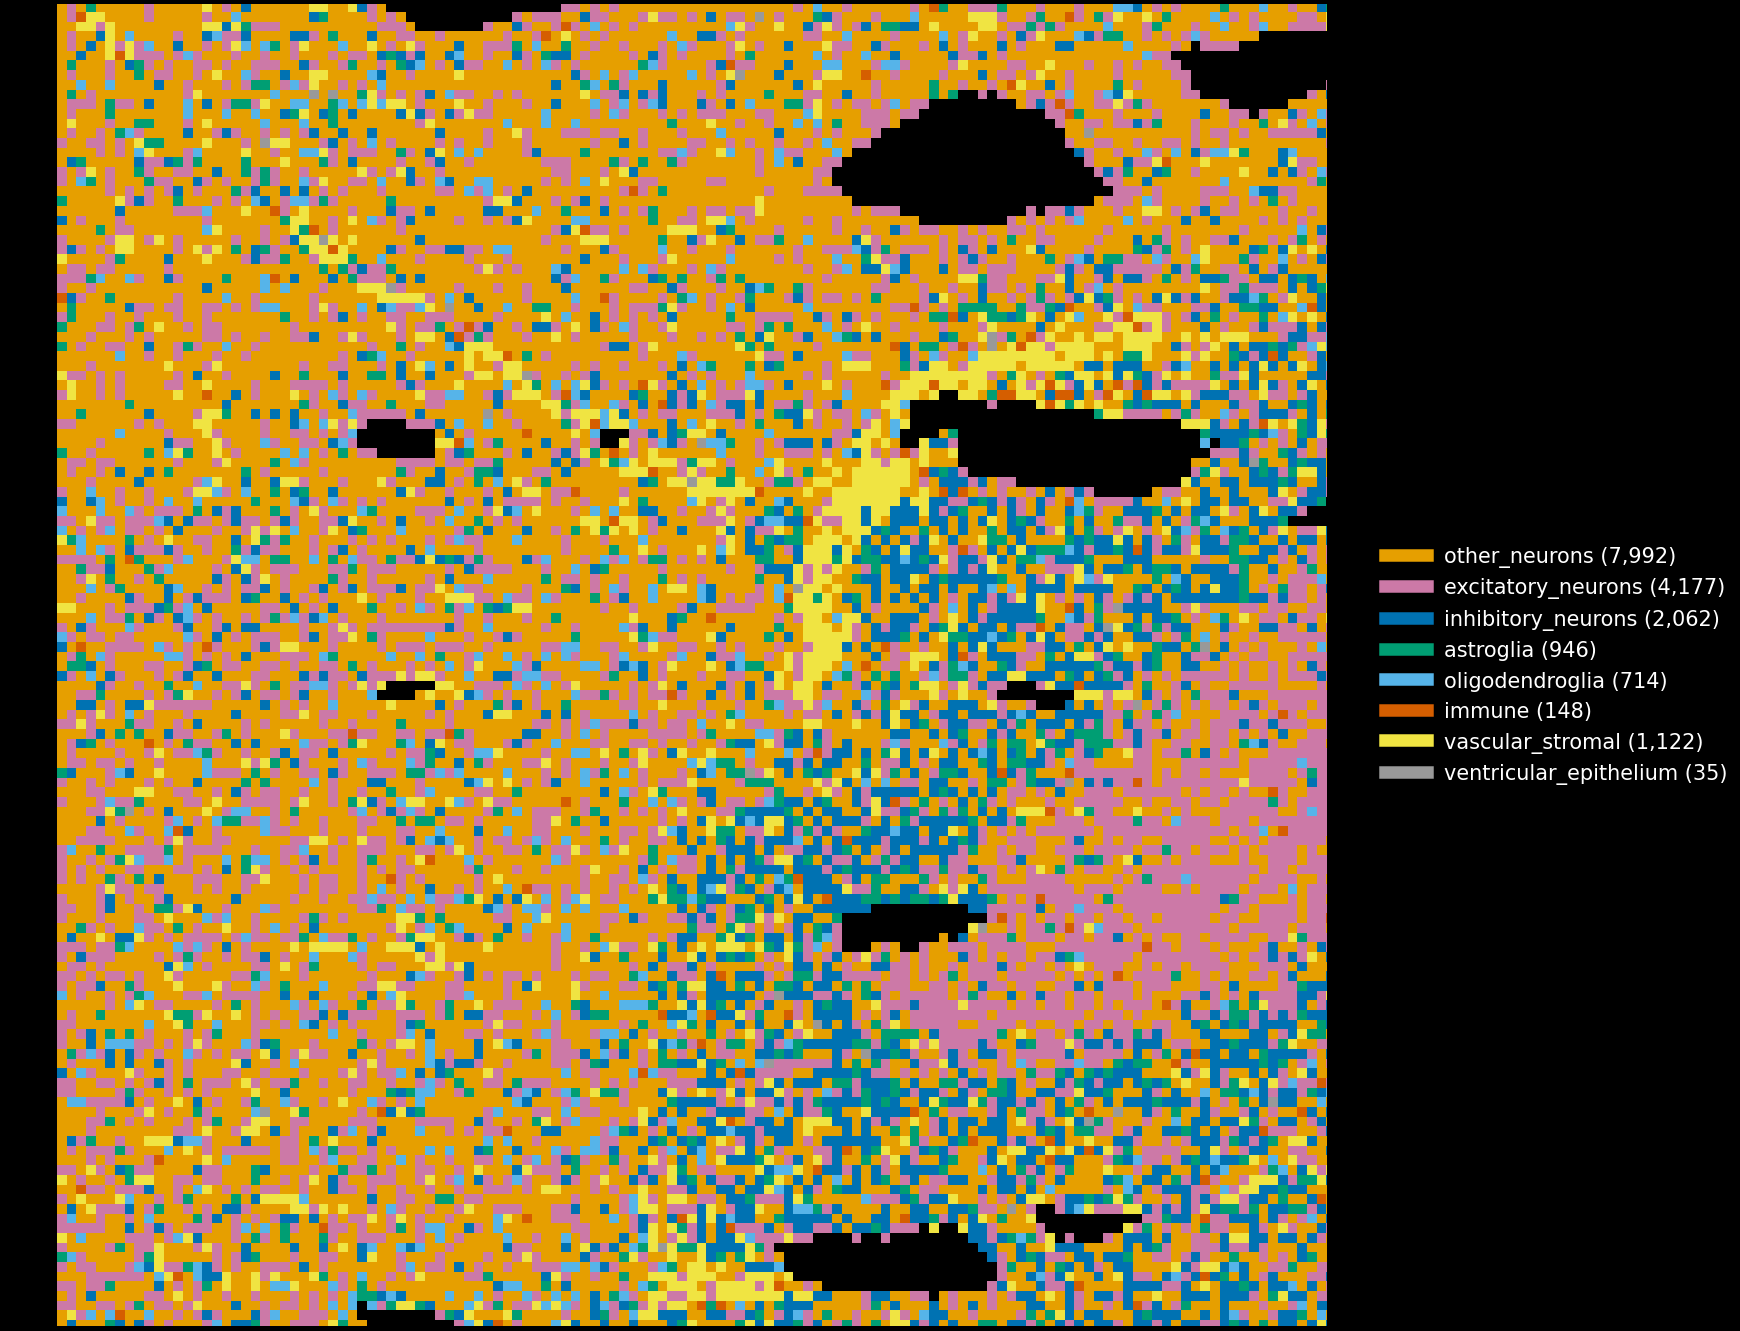

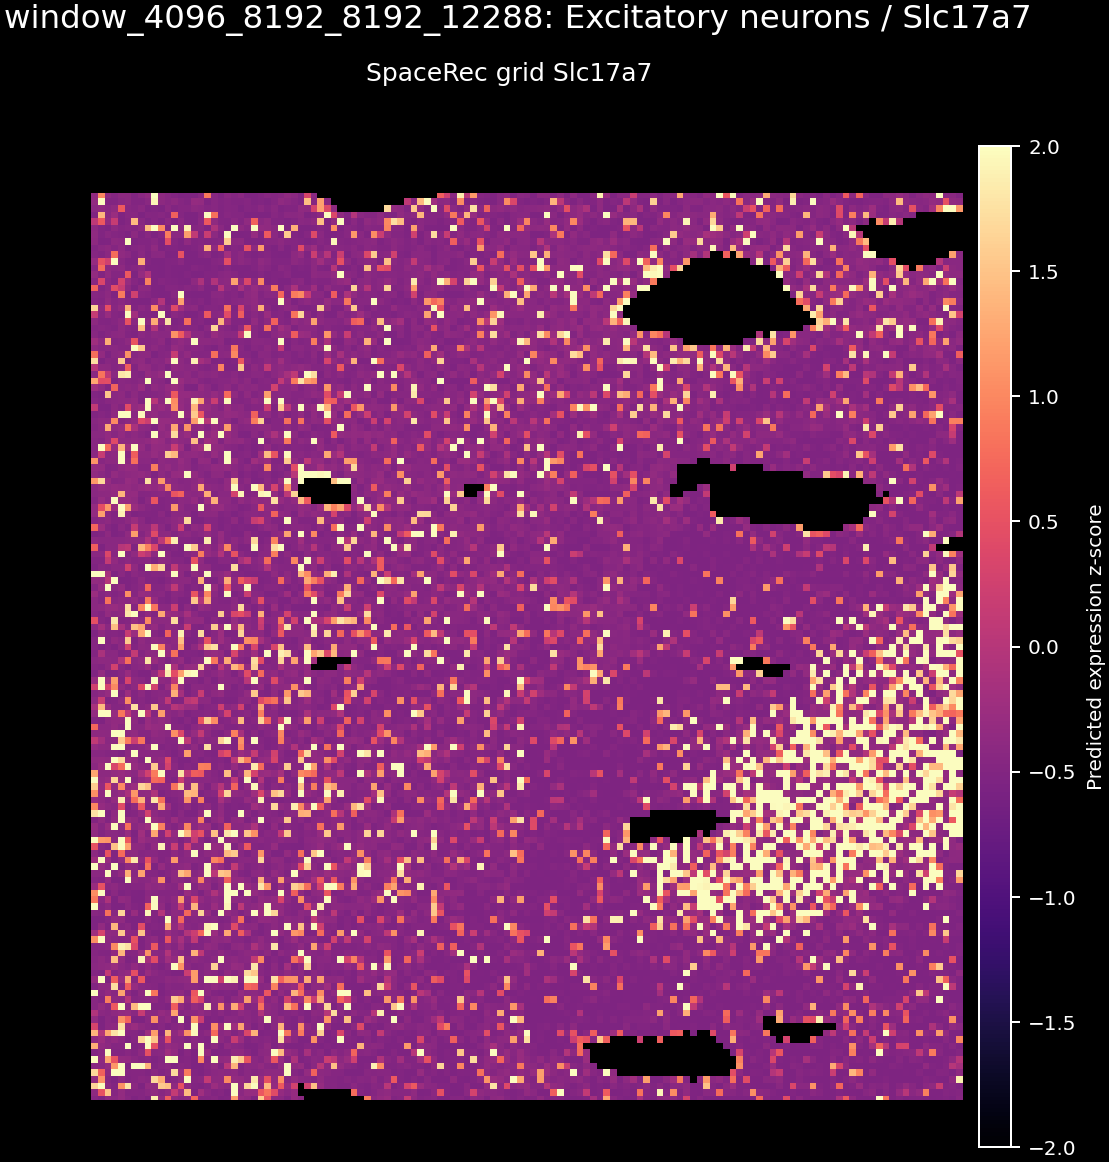

{'predicted_type': PosixPath('/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/model_pred/train/metrics/windows/window_4096_8192_8192_12288/predicted_type.png'),
 'Slc17a7_expression': PosixPath('/ocean/projects/bio260060p/gwang17/SpaceRec_project/resources/cerebellum/C2/model_pred/train/metrics/windows/window_4096_8192_8192_12288/Excitatory_neurons_Slc17a7_grid_expr.png')}

In [9]:
from IPython.display import Image, display

window_dir = paths['windows'] / 'window_4096_8192_8192_12288'
predicted_type_png = window_dir / 'predicted_type.png'
slc17a7_png = window_dir / 'Excitatory_neurons_Slc17a7_grid_expr.png'
require_files(predicted_type_png, slc17a7_png)
display(Image(filename=str(predicted_type_png)))
display(Image(filename=str(slc17a7_png)))
{'predicted_type': predicted_type_png, 'Slc17a7_expression': slc17a7_png}